# Decision tree: will a Chicago traffic crash result in an injury?

Target: INJURIES_TOTAL > 0

Follows the same structure as the logistic regression and random forest scripts: same data loading,
features, split, seed, metrics, thresholds, bootstrap, subgroup and robustness definitions.
Only the model differs. Decision-tree-specific additions are marked "(ADDED)".

In [3]:
%matplotlib inline
import os
import time
import pickle
import hashlib
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression  # used only for Platt calibration
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore")

## CONFIG

`DATA_PATH` must be the same CSV the other two notebooks used, and `SPLIT_MODE` must match. Re-run this cell after changing anything here.

In [4]:
DATA_PATH = "crashes.csv"   # <- must be the SAME file used in the random forest notebook
SPLIT_MODE = "random"      # "random" or "temporal" (train on earliest, test on latest)
USE_CONTRIBUTORY_CAUSE = False  # PRIM/SEC causes are assigned post-investigation; keep False
USE_CLASS_WEIGHT = False   # False keeps probabilities calibrated; True boosts recall
GRID = dict(max_depth=[6, 8, 12, None], min_samples_leaf=[50, 100, 200, 500])
TAG = "dt"                 # output file prefix, so nothing overwrites the other models' files
N_BOOT = 200
SEED = 42
# ============================================================================

## 1. LOAD

In [5]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [c.strip().upper() for c in df.columns]
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")

df = df[df["INJURIES_TOTAL"].notna()].copy()
df["y"] = (df["INJURIES_TOTAL"] > 0).astype(int)
print(f"Injury rate: {df['y'].mean():.3%}  (n={len(df):,})")

df["CRASH_DATE"] = pd.to_datetime(df["CRASH_DATE"], errors="coerce")
df = df[df["CRASH_DATE"].notna()].copy()

Loaded 405,144 rows, 49 columns
Injury rate: 16.596%  (n=404,199)


## 2. FEATURES

In [6]:
# Leakage excluded on purpose: INJURIES_*, MOST_SEVERE_INJURY, CRASH_TYPE (defines the
# label), DAMAGE, DATE_POLICE_NOTIFIED, REPORT_TYPE (all post-crash), plus ID/address cols.
df["HOUR_SIN"] = np.sin(2 * np.pi * df["CRASH_HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["CRASH_HOUR"] / 24)
df["IS_WEEKEND"] = df["CRASH_DAY_OF_WEEK"].isin([1, 7]).astype(int)  # 1=Sun, 7=Sat

NUM_COLS = ["POSTED_SPEED_LIMIT", "LANE_CNT", "NUM_UNITS", "CRASH_HOUR",
            "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH"]
CAT_COLS = ["TRAFFIC_CONTROL_DEVICE", "DEVICE_CONDITION", "WEATHER_CONDITION",
            "LIGHTING_CONDITION", "FIRST_CRASH_TYPE", "TRAFFICWAY_TYPE", "ALIGNMENT",
            "ROADWAY_SURFACE_COND", "ROAD_DEFECT", "INTERSECTION_RELATED_I",
            "NOT_RIGHT_OF_WAY_I", "HIT_AND_RUN_I", "CRASH_DAY_OF_WEEK"]
if USE_CONTRIBUTORY_CAUSE:
    CAT_COLS += ["PRIM_CONTRIBUTORY_CAUSE", "SEC_CONTRIBUTORY_CAUSE"]

NUM_COLS = [c for c in NUM_COLS if c in df.columns]
CAT_COLS = [c for c in CAT_COLS if c in df.columns]
FEATURES = NUM_COLS + CAT_COLS

for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in CAT_COLS:
    df[c] = df[c].astype(str).replace({"nan": "MISSING", "": "MISSING"}).fillna("MISSING")

## 3. SPLIT

The fingerprint printed here must equal the other notebooks' (`ab504b8b` in the group's run).

In [7]:
if SPLIT_MODE == "temporal":
    df = df.sort_values("CRASH_DATE").reset_index(drop=True)
    n = len(df)
    tr, va, te = df.iloc[:int(.6 * n)], df.iloc[int(.6 * n):int(.8 * n)], df.iloc[int(.8 * n):]
else:
    tr, tmp = train_test_split(df, test_size=0.4, stratify=df["y"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["y"], random_state=SEED)

X_tr, y_tr = tr[FEATURES], tr["y"].values
X_va, y_va = va[FEATURES], va["y"].values
X_te, y_te = te[FEATURES], te["y"].values
print(f"Split ({SPLIT_MODE}): train={len(tr):,} val={len(va):,} test={len(te):,}")

# (ADDED) must equal the other models' fingerprint
print("Test-set fingerprint:", hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8])
print("Features used:", FEATURES)

Split (random): train=242,519 val=80,840 test=80,840
Test-set fingerprint: ab504b8b
Features used: ['POSTED_SPEED_LIMIT', 'LANE_CNT', 'NUM_UNITS', 'CRASH_HOUR', 'HOUR_SIN', 'HOUR_COS', 'IS_WEEKEND', 'CRASH_MONTH', 'TRAFFIC_CONTROL_DEVICE', 'DEVICE_CONDITION', 'WEATHER_CONDITION', 'LIGHTING_CONDITION', 'FIRST_CRASH_TYPE', 'TRAFFICWAY_TYPE', 'ALIGNMENT', 'ROADWAY_SURFACE_COND', 'ROAD_DEFECT', 'INTERSECTION_RELATED_I', 'NOT_RIGHT_OF_WAY_I', 'HIT_AND_RUN_I', 'CRASH_DAY_OF_WEEK']


## 4. HELPERS

In [8]:
def build_pipe(num_cols, cat_cols, **tree_params):
    # Same preprocessing as the other models (scaling is harmless to trees; kept so inputs are identical).
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ])
    clf = DecisionTreeClassifier(random_state=SEED,
                                 class_weight="balanced" if USE_CLASS_WEIGHT else None, **tree_params)
    return Pipeline([("pre", pre), ("clf", clf)])


def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def metrics(y, p, thr=0.5):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    yhat = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, yhat),
        "mcc": matthews_corrcoef(y, yhat),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "log_loss": log_loss(y, p),
        "brier": brier_score_loss(y, p),
        "ece": ece_score(y, p),
    }


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[np.argmax(f1)]


def recall_target_threshold(y, p, target=0.90):
    """Highest threshold that still achieves >= target recall."""
    _, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[-1]] if len(ok) else thr[0]

## 5. TUNE TREE SETTINGS ON VALIDATION

16 small trees, so this takes a few minutes at most. If the best settings land on the edge of the grid, widen `GRID` in CONFIG and note it in the report.

In [9]:
print("\n=== Hyperparameter tuning (validation log loss) ===")
tune_rows = []
for depth, leaf in itertools.product(GRID["max_depth"], GRID["min_samples_leaf"]):
    t0 = time.perf_counter()
    pipe = build_pipe(NUM_COLS, CAT_COLS, max_depth=depth, min_samples_leaf=leaf).fit(X_tr, y_tr)
    ll = log_loss(y_va, np.clip(pipe.predict_proba(X_va)[:, 1], 1e-7, 1 - 1e-7))
    tune_rows.append(dict(max_depth=depth, min_samples_leaf=leaf, val_log_loss=ll,
                          n_leaves=pipe.named_steps["clf"].get_n_leaves(),
                          fit_s=round(time.perf_counter() - t0, 1)))
    print(f"depth={str(depth):<5} leaf={leaf:<4} val log loss={ll:.4f}  "
          f"(leaves={tune_rows[-1]['n_leaves']}, {tune_rows[-1]['fit_s']}s)")
tune_df = pd.DataFrame(tune_rows).sort_values("val_log_loss")
tune_df.to_csv(f"{TAG}_tuning.csv", index=False)
b = tune_df.iloc[0]
BEST = dict(max_depth=None if pd.isna(b["max_depth"]) else int(b["max_depth"]),
            min_samples_leaf=int(b["min_samples_leaf"]))
print("Best params:", BEST)


=== Hyperparameter tuning (validation log loss) ===
depth=6     leaf=50   val log loss=0.3554  (leaves=58, 2.9s)
depth=6     leaf=100  val log loss=0.3553  (leaves=50, 2.9s)
depth=6     leaf=200  val log loss=0.3553  (leaves=42, 2.9s)
depth=6     leaf=500  val log loss=0.3553  (leaves=32, 2.9s)
depth=8     leaf=50   val log loss=0.3522  (leaves=133, 3.4s)
depth=8     leaf=100  val log loss=0.3517  (leaves=110, 3.4s)
depth=8     leaf=200  val log loss=0.3521  (leaves=90, 3.4s)
depth=8     leaf=500  val log loss=0.3523  (leaves=66, 3.2s)
depth=12    leaf=50   val log loss=0.3540  (leaves=539, 4.9s)
depth=12    leaf=100  val log loss=0.3514  (leaves=407, 4.7s)
depth=12    leaf=200  val log loss=0.3497  (leaves=289, 5.0s)
depth=12    leaf=500  val log loss=0.3499  (leaves=181, 4.1s)
depth=None  leaf=50   val log loss=0.4090  (leaves=3309, 11.6s)
depth=None  leaf=100  val log loss=0.3667  (leaves=1705, 9.0s)
depth=None  leaf=200  val log loss=0.3541  (leaves=866, 7.9s)
depth=None  leaf=500

## 6. FINAL FIT + EFFICIENCY

In [10]:
t0 = time.perf_counter()
model = build_pipe(NUM_COLS, CAT_COLS, **BEST).fit(X_tr, y_tr)
train_time = time.perf_counter() - t0

t0 = time.perf_counter()
p_te = model.predict_proba(X_te)[:, 1]
infer_time = time.perf_counter() - t0
p_va = model.predict_proba(X_va)[:, 1]
p_tr = model.predict_proba(X_tr)[:, 1]

size_kb = len(pickle.dumps(model)) / 1024
print("\n=== Computational efficiency ===")
print(f"Train time: {train_time:.2f}s | Inference: {1000 * infer_time / len(X_te) * 1000:.3f} ms per 1,000 rows "
      f"| Model size: {size_kb:.1f} KB")


=== Computational efficiency ===
Train time: 4.53s | Inference: 2.281 ms per 1,000 rows | Model size: 51.8 KB


## 7. THRESHOLDS (CHOSEN ON VALIDATION)

In [11]:
thr_f1 = best_f1_threshold(y_va, p_va)
thr_rec90 = recall_target_threshold(y_va, p_va, 0.90)
thresholds = {"default_0.5": 0.5, "max_F1": thr_f1, "recall>=0.90": thr_rec90}
print("\nThresholds picked on validation:", {k: round(float(v), 3) for k, v in thresholds.items()})


Thresholds picked on validation: {'default_0.5': 0.5, 'max_F1': 0.249, 'recall>=0.90': 0.101}


## 8. MAIN METRICS + GENERALIZATION

In [12]:
print("\n=== Test-set metrics at each threshold ===")
rows = {name: metrics(y_te, p_te, t) for name, t in thresholds.items()}
print(pd.DataFrame(rows).T.round(4).to_string())

print("\n=== Generalization (train / val / test at max-F1 threshold) ===")
gen = pd.DataFrame({
    "train": metrics(y_tr, p_tr, thr_f1),
    "val": metrics(y_va, p_va, thr_f1),
    "test": metrics(y_te, p_te, thr_f1),
}).T
print(gen[["accuracy", "f1", "roc_auc", "pr_auc", "log_loss"]].round(4).to_string())

print("\n=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===")
print(confusion_matrix(y_te, (p_te >= thr_f1).astype(int)))


=== Test-set metrics at each threshold ===
              accuracy  precision  recall      f1  balanced_acc     mcc  roc_auc  pr_auc  log_loss   brier     ece
default_0.5     0.8649     0.7602  0.2719  0.4005        0.6274  0.4012   0.7982  0.5218    0.3513  0.1061  0.0042
max_F1          0.8223     0.4670  0.5028  0.4843        0.6943  0.3775   0.7982  0.5218    0.3513  0.1061  0.0042
recall>=0.90    0.5317     0.2486  0.9003  0.3896        0.6794  0.2726   0.7982  0.5218    0.3513  0.1061  0.0042

=== Generalization (train / val / test at max-F1 threshold) ===
       accuracy      f1  roc_auc  pr_auc  log_loss
train    0.8247  0.4907   0.8048  0.5305    0.3464
val      0.8246  0.4885   0.8006  0.5249    0.3497
test     0.8223  0.4843   0.7982  0.5218    0.3513

=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===
[[59726  7698]
 [ 6670  6746]]


## 9. BOOTSTRAP CIs

In [13]:
print(f"\n=== Bootstrap 95% CIs ({N_BOOT} resamples, test set) ===")
rng = np.random.default_rng(SEED)
boot = {"roc_auc": [], "pr_auc": [], "log_loss": [], "f1": [], "recall": []}
for _ in range(N_BOOT):
    i = rng.integers(0, len(y_te), len(y_te))
    yb, pb = y_te[i], p_te[i]
    if yb.min() == yb.max():
        continue
    m = metrics(yb, pb, thr_f1)
    for k in boot:
        boot[k].append(m[k])
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:<9} {np.mean(v):.4f}  [{lo:.4f}, {hi:.4f}]")


=== Bootstrap 95% CIs (200 resamples, test set) ===
roc_auc   0.7981  [0.7935, 0.8019]
pr_auc    0.5214  [0.5142, 0.5306]
log_loss  0.3512  [0.3466, 0.3557]
f1        0.4838  [0.4763, 0.4908]
recall    0.5024  [0.4939, 0.5096]


## 10. CALIBRATION

In [14]:
# Calibrators are fit on VALIDATION predictions, evaluated on TEST.
print("\n=== Calibration (fit on validation, evaluated on test) ===")
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
platt = LogisticRegression(C=1e6).fit(logit(p_va).reshape(-1, 1), y_va)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_va, y_va)
p_platt = platt.predict_proba(logit(p_te).reshape(-1, 1))[:, 1]
p_iso = iso.predict(p_te)
calib = pd.DataFrame({
    "uncalibrated": metrics(y_te, p_te, thr_f1),
    "platt": metrics(y_te, p_platt, thr_f1),
    "isotonic": metrics(y_te, p_iso, thr_f1),
}).T
print(calib[["log_loss", "brier", "ece", "roc_auc", "pr_auc"]].round(4).to_string())


=== Calibration (fit on validation, evaluated on test) ===
              log_loss   brier     ece  roc_auc  pr_auc
uncalibrated    0.3513  0.1061  0.0042   0.7982  0.5218
platt           0.3512  0.1061  0.0031   0.7982  0.5218
isotonic        0.3502  0.1061  0.0040   0.7983  0.5170


## 11. SUBGROUP PERFORMANCE

In [15]:
print("\n=== Subgroup performance (test, max-F1 threshold) ===")
te_eval = te.copy()
te_eval["p"] = p_te
te_eval["SPEED_BIN"] = pd.cut(te_eval["POSTED_SPEED_LIMIT"], [-1, 25, 30, 35, 100],
                              labels=["<=25", "26-30", "31-35", ">35"]).astype(str)
te_eval["TIME_OF_DAY"] = pd.cut(te_eval["CRASH_HOUR"], [-1, 5, 11, 17, 23],
                                labels=["night", "morning", "afternoon", "evening"]).astype(str)
te_eval["WEEKEND"] = te_eval["IS_WEEKEND"].map({0: "weekday", 1: "weekend"})

sub_rows = []
for col in ["LIGHTING_CONDITION", "WEATHER_CONDITION", "SPEED_BIN", "TIME_OF_DAY", "WEEKEND"]:
    for g, d in te_eval.groupby(col):
        if len(d) < 200:
            continue
        yy, pp = d["y"].values, d["p"].values
        yh = (pp >= thr_f1).astype(int)
        sub_rows.append({
            "feature": col, "group": g, "n": len(d), "injury_rate": yy.mean(),
            "mean_pred": pp.mean(),
            "recall": recall_score(yy, yh, zero_division=0),
            "precision": precision_score(yy, yh, zero_division=0),
            "roc_auc": roc_auc_score(yy, pp) if yy.min() != yy.max() else np.nan,
            "ece": ece_score(yy, pp),
        })
sub = pd.DataFrame(sub_rows)
print(sub.round(3).to_string(index=False))
sub.to_csv(f"{TAG}_subgroup_results.csv", index=False)


=== Subgroup performance (test, max-F1 threshold) ===
           feature                  group     n  injury_rate  mean_pred  recall  precision  roc_auc   ece
LIGHTING_CONDITION               DARKNESS  3578        0.159      0.166   0.542      0.429    0.795 0.013
LIGHTING_CONDITION DARKNESS, LIGHTED ROAD 18374        0.205      0.200   0.597      0.424    0.783 0.010
LIGHTING_CONDITION                   DAWN  1346        0.198      0.180   0.500      0.500    0.776 0.027
LIGHTING_CONDITION               DAYLIGHT 54245        0.154      0.156   0.457      0.498    0.796 0.004
LIGHTING_CONDITION                   DUSK  2184        0.173      0.174   0.519      0.483    0.808 0.008
LIGHTING_CONDITION                UNKNOWN  1113        0.056      0.080   0.565      0.473    0.898 0.031
 WEATHER_CONDITION                  CLEAR 68042        0.164      0.164   0.505      0.475    0.804 0.003
 WEATHER_CONDITION        CLOUDY/OVERCAST  2570        0.165      0.163   0.504      0.506    0.8

## 12. ROBUSTNESS

In [16]:
print("\n=== Robustness (test set) ===")
rob = {"clean": metrics(y_te, p_te, thr_f1)}

# (a) Inject missing values at 10/30/50%
for frac in [0.1, 0.3, 0.5]:
    Xm = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in CAT_COLS:
        Xm.loc[r.random(len(Xm)) < frac, c] = "MISSING"
    for c in ["POSTED_SPEED_LIMIT", "LANE_CNT", "CRASH_HOUR"]:
        Xm.loc[r.random(len(Xm)) < frac, c] = np.nan
    rob[f"missing_{int(frac * 100)}%"] = metrics(y_te, model.predict_proba(Xm)[:, 1], thr_f1)

# (b) Gaussian noise on numeric features (scaled to each feature's std)
for s in [0.25, 0.5, 1.0]:
    Xn = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in ["POSTED_SPEED_LIMIT", "CRASH_HOUR", "NUM_UNITS"]:
        Xn[c] = Xn[c] + r.normal(0, s * X_tr[c].std(), len(Xn))
    rob[f"noise_{s}sd"] = metrics(y_te, model.predict_proba(Xn)[:, 1], thr_f1)

# (c) Drop feature groups and retrain
groups = {
    "no_weather": ["WEATHER_CONDITION", "ROADWAY_SURFACE_COND", "ROAD_DEFECT"],
    "no_lighting": ["LIGHTING_CONDITION"],
    "no_time": ["CRASH_HOUR", "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH", "CRASH_DAY_OF_WEEK"],
    "no_crash_type": ["FIRST_CRASH_TYPE"],
}
for name, drop in groups.items():
    nc = [c for c in NUM_COLS if c not in drop]
    cc = [c for c in CAT_COLS if c not in drop]
    m2 = build_pipe(nc, cc, **BEST).fit(X_tr[nc + cc], y_tr)
    rob[f"drop_{name}"] = metrics(y_te, m2.predict_proba(X_te[nc + cc])[:, 1], thr_f1)

rob_df = pd.DataFrame(rob).T
print(rob_df[["accuracy", "f1", "recall", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
rob_df.to_csv(f"{TAG}_robustness_results.csv")


=== Robustness (test set) ===
                    accuracy      f1  recall  roc_auc  pr_auc  log_loss     ece
clean                 0.8223  0.4843  0.5028   0.7982  0.5218    0.3513  0.0042
missing_10%           0.8207  0.4601  0.4604   0.7809  0.4952    0.3612  0.0043
missing_30%           0.8167  0.4073  0.3795   0.7425  0.4343    0.3815  0.0076
missing_50%           0.8129  0.3513  0.3053   0.7013  0.3743    0.4002  0.0127
noise_0.25sd          0.8224  0.4842  0.5023   0.7978  0.5223    0.3517  0.0048
noise_0.5sd           0.8172  0.4783  0.5048   0.7946  0.5178    0.3542  0.0072
noise_1.0sd           0.7730  0.4397  0.5367   0.7736  0.4924    0.3699  0.0249
drop_no_weather       0.8216  0.4856  0.5073   0.7978  0.5219    0.3517  0.0042
drop_no_lighting      0.8230  0.4844  0.5008   0.7981  0.5218    0.3513  0.0042
drop_no_time          0.8327  0.4863  0.4773   0.7996  0.5227    0.3504  0.0041
drop_no_crash_type    0.7609  0.3512  0.3900   0.6878  0.3006    0.4179  0.0064


## 13. UNCERTAINTY

In [17]:
print("\n=== Uncertainty ===")
pc = np.clip(p_te, 1e-7, 1 - 1e-7)
entropy = -(pc * np.log2(pc) + (1 - pc) * np.log2(1 - pc))
correct = ((p_te >= thr_f1).astype(int) == y_te)
print(f"Mean predictive entropy (bits): correct={entropy[correct].mean():.3f} | incorrect={entropy[~correct].mean():.3f}")
conf = np.maximum(p_te, 1 - p_te)
print(f"Mean confidence: correct={conf[correct].mean():.3f} | incorrect={conf[~correct].mean():.3f}")
print("Accuracy by confidence quartile:")
q = pd.qcut(conf, 4, duplicates="drop")
print(pd.DataFrame({"correct": correct, "q": q}).groupby("q").correct.agg(["mean", "size"]).round(3).to_string())

# (ADDED) Leaf support: a tree's probability is the injury share inside one leaf, so small leaves are less reliable
tree_ = model.named_steps["clf"]
leaf_size = tree_.tree_.n_node_samples[tree_.apply(model.named_steps["pre"].transform(X_te))]
ql = pd.qcut(leaf_size, 4, duplicates="drop")
print("Error rate by leaf-size quartile (smallest leaves first):")
print(pd.DataFrame({"error_rate": ~correct, "q": ql}).groupby("q", observed=True).error_rate.agg(["mean", "size"]).round(3).to_string())


=== Uncertainty ===
Mean predictive entropy (bits): correct=0.447 | incorrect=0.740
Mean confidence: correct=0.888 | incorrect=0.760
Accuracy by confidence quartile:
                 mean   size
q                           
(0.499, 0.808]  0.550  20524
(0.808, 0.871]  0.862  24658
(0.871, 0.952]  0.926  16252
(0.952, 1.0]    0.973  19406
Error rate by leaf-size quartile (smallest leaves first):
                     mean   size
q                               
(200.999, 407.0]    0.253  20341
(407.0, 2916.0]     0.186  20541
(2916.0, 14335.0]   0.139  22839
(14335.0, 51253.0]  0.129  17119


## 14. INTERPRETABILITY

Includes readable if/then rules from the top of the tree, which is this model's main advantage.

In [18]:
tree = model.named_steps["clf"]
print(f"\n=== Fitted tree: depth={tree.get_depth()}, leaves={tree.get_n_leaves()} ===")
print("\n=== Top decision tree importances (impurity, one-hot level) ===")
names = model.named_steps["pre"].get_feature_names_out()
imp_df = pd.DataFrame({"feature": names, "importance": tree.feature_importances_}).sort_values("importance", ascending=False)
print(imp_df.head(15).round(4).to_string(index=False))
imp_df.to_csv(f"{TAG}_importance.csv", index=False)

# (ADDED) The first levels of the tree as readable if/then rules
rules = export_text(tree, feature_names=list(names), max_depth=3)
print("\n=== First three levels of the tree ===")
print(rules)
open(f"{TAG}_tree_rules.txt", "w").write(export_text(tree, feature_names=list(names), max_depth=5))

print("\n=== Permutation importance (original columns, PR-AUC drop, 20k test sample) ===")
samp = np.random.default_rng(SEED).choice(len(X_te), size=min(20000, len(X_te)), replace=False)
pi = permutation_importance(model, X_te.iloc[samp], y_te[samp], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                      "std": pi.importances_std}).sort_values("importance", ascending=False)
print(pi_df.round(4).to_string(index=False))
pi_df.to_csv(f"{TAG}_permutation_importance.csv", index=False)


=== Fitted tree: depth=12, leaves=289 ===

=== Top decision tree importances (impurity, one-hot level) ===
                                       feature  importance
              cat__FIRST_CRASH_TYPE_PEDESTRIAN      0.4206
            cat__FIRST_CRASH_TYPE_PEDALCYCLIST      0.2057
           cat__INTERSECTION_RELATED_I_MISSING      0.1115
                                num__NUM_UNITS      0.0675
    cat__FIRST_CRASH_TYPE_PARKED MOTOR VEHICLE      0.0412
                   cat__FIRST_CRASH_TYPE_ANGLE      0.0333
cat__FIRST_CRASH_TYPE_SIDESWIPE SAME DIRECTION      0.0311
                          cat__HIT_AND_RUN_I_Y      0.0189
                                 num__HOUR_COS      0.0113
                       num__POSTED_SPEED_LIMIT      0.0077
                               num__CRASH_HOUR      0.0068
    cat__TRAFFIC_CONTROL_DEVICE_TRAFFIC SIGNAL      0.0065
                 cat__FIRST_CRASH_TYPE_HEAD ON      0.0065
                cat__FIRST_CRASH_TYPE_REAR END      0.0037
       

## 15. PLOTS

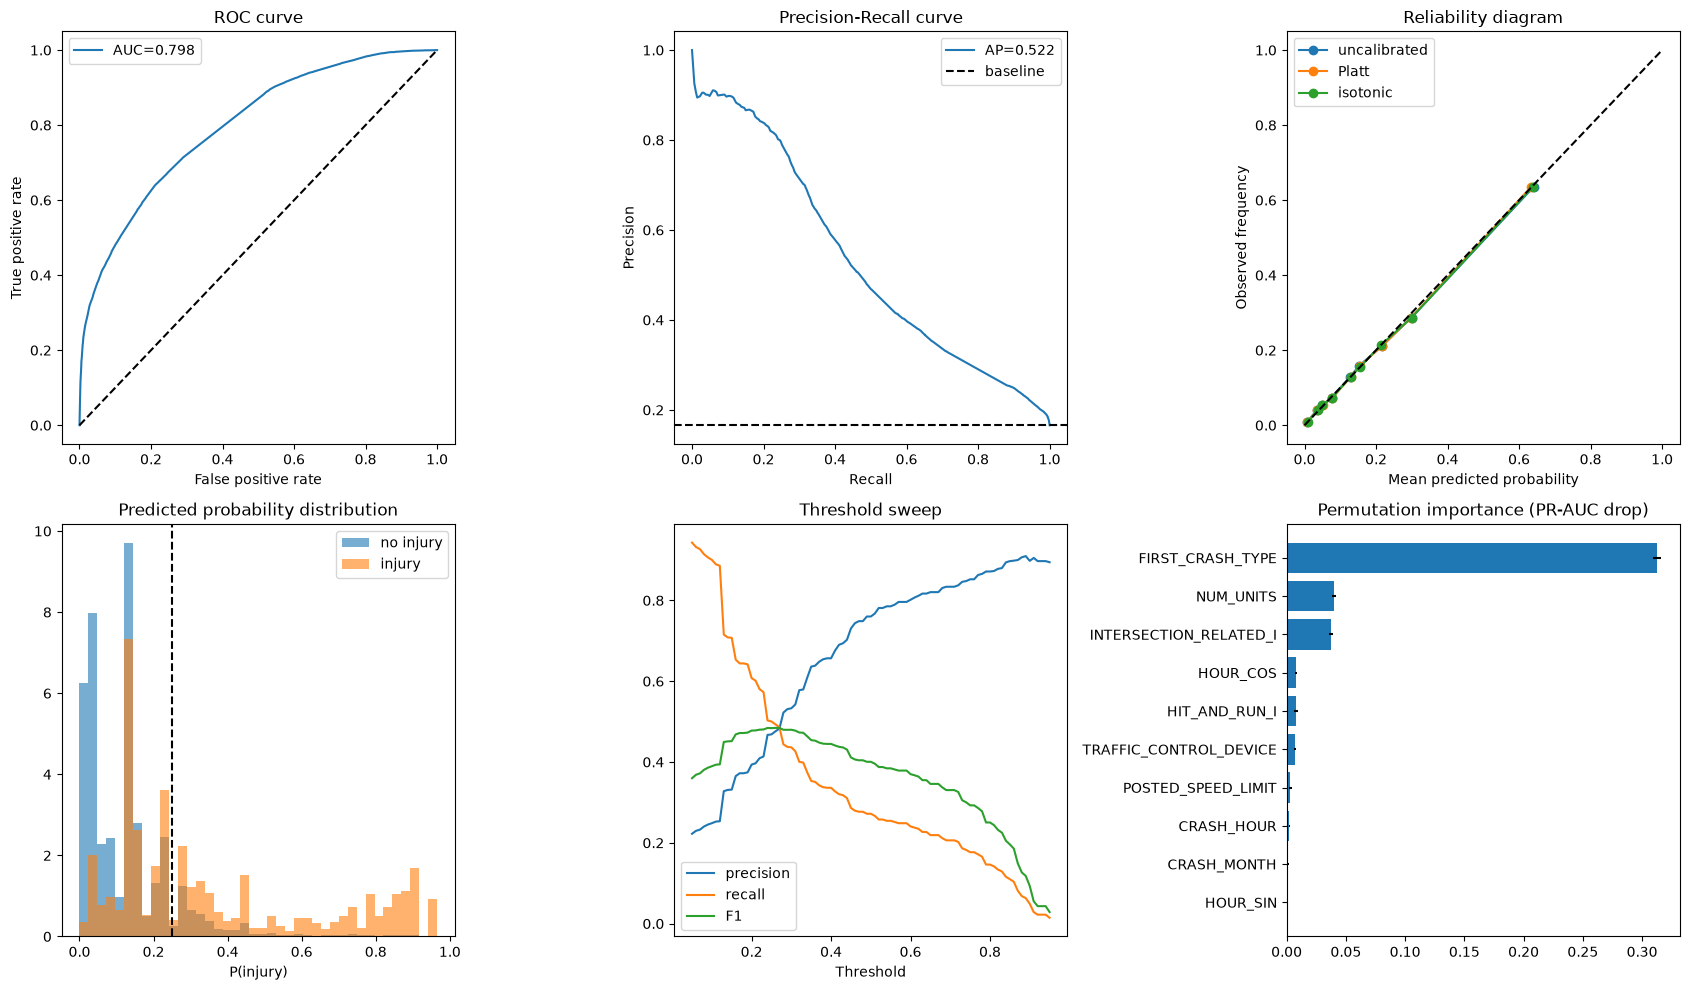


Saved: dt_evaluation.png, dt_subgroup_results.csv, dt_robustness_results.csv, dt_importance.csv, dt_permutation_importance.csv, dt_tuning.csv, dt_tree_rules.txt


In [19]:
fig, ax = plt.subplots(2, 3, figsize=(17, 10))

fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0, 0].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_te, p_te):.3f}")
ax[0, 0].plot([0, 1], [0, 1], "k--")
ax[0, 0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax[0, 0].legend()

prec, rec, _ = precision_recall_curve(y_te, p_te)
ax[0, 1].plot(rec, prec, label=f"AP={average_precision_score(y_te, p_te):.3f}")
ax[0, 1].axhline(y_te.mean(), color="k", ls="--", label="baseline")
ax[0, 1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
ax[0, 1].legend()

for lbl, pp in [("uncalibrated", p_te), ("Platt", p_platt), ("isotonic", p_iso)]:
    fr, mp = calibration_curve(y_te, pp, n_bins=10, strategy="quantile")
    ax[0, 2].plot(mp, fr, "o-", label=lbl)
ax[0, 2].plot([0, 1], [0, 1], "k--")
ax[0, 2].set(title="Reliability diagram", xlabel="Mean predicted probability", ylabel="Observed frequency")
ax[0, 2].legend()

ax[1, 0].hist(p_te[y_te == 0], bins=40, alpha=.6, label="no injury", density=True)
ax[1, 0].hist(p_te[y_te == 1], bins=40, alpha=.6, label="injury", density=True)
ax[1, 0].axvline(thr_f1, color="k", ls="--")
ax[1, 0].set(title="Predicted probability distribution", xlabel="P(injury)")
ax[1, 0].legend()

ths = np.linspace(0.05, 0.95, 91)
ax[1, 1].plot(ths, [precision_score(y_te, p_te >= t, zero_division=0) for t in ths], label="precision")
ax[1, 1].plot(ths, [recall_score(y_te, p_te >= t) for t in ths], label="recall")
ax[1, 1].plot(ths, [f1_score(y_te, p_te >= t) for t in ths], label="F1")
ax[1, 1].set(title="Threshold sweep", xlabel="Threshold")
ax[1, 1].legend()

top = pi_df.head(10).iloc[::-1]
ax[1, 2].barh(top["feature"], top["importance"], xerr=top["std"])
ax[1, 2].set(title="Permutation importance (PR-AUC drop)")

plt.tight_layout()
plt.savefig(f"{TAG}_evaluation.png", dpi=150)
plt.show()
print(f"\nSaved: {TAG}_evaluation.png, {TAG}_subgroup_results.csv, {TAG}_robustness_results.csv, "
      f"{TAG}_importance.csv, {TAG}_permutation_importance.csv, {TAG}_tuning.csv, {TAG}_tree_rules.txt")

## 16. SAVE FILES FOR COMPARISON (ADDED)

Writes the `dt_*` files used for the head-to-head comparison.

In [20]:
# Same layout as the other models' files so the three can be compared directly.
out = pd.DataFrame({"y_true": y_te, "p_dt": p_te, "p_dt_platt": p_platt, "p_dt_isotonic": p_iso},
                   index=te.index)
if "CRASH_RECORD_ID" in te.columns:
    out.insert(0, "CRASH_RECORD_ID", te["CRASH_RECORD_ID"].values)
out.to_csv(f"{TAG}_test_predictions.csv", index_label="row_index")

pd.DataFrame(rows).T.to_csv(f"{TAG}_test_metrics_by_threshold.csv")
gen.to_csv(f"{TAG}_generalization.csv")
calib.to_csv(f"{TAG}_calibration.csv")
pd.DataFrame({k: [np.mean(v), *np.percentile(v, [2.5, 97.5])] for k, v in boot.items()},
             index=["mean", "ci_low", "ci_high"]).T.to_csv(f"{TAG}_bootstrap.csv")
pd.Series({
    "train_time_s": train_time,
    "inference_ms_per_1000_rows": 1000 * infer_time / len(X_te) * 1000,
    "model_size_kb": size_kb,
    "cpu_cores": os.cpu_count(),
    "max_depth": str(BEST["max_depth"]),
    "min_samples_leaf": BEST["min_samples_leaf"],
    "tree_depth": model.named_steps["clf"].get_depth(),
    "n_leaves": model.named_steps["clf"].get_n_leaves(),
    "threshold_max_f1": thr_f1,
    "threshold_recall90": thr_rec90,
    "test_rows": len(y_te),
    "test_fingerprint": hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8],
}).to_csv(f"{TAG}_run_info.csv", header=["value"])
print(f"Saved {TAG}_* comparison files")

Saved dt_* comparison files


## 17. SHIFT TESTS (ADDED)

Same seasonal and held-out-beat definitions as the other two models.

In [21]:
# Same definitions as the other models' shift tests, so the results are comparable.
RUN_EXTRAS = True
if RUN_EXTRAS:
    print("\n=== Distribution shift (max-F1 threshold from validation) ===")
    shift = {"test (reference)": metrics(y_te, p_te, thr_f1)}

    # (a) Seasonal shift: train on warm months (Apr-Oct), test on warm vs winter
    warm = [4, 5, 6, 7, 8, 9, 10]
    tr_w = tr[tr["CRASH_MONTH"].isin(warm)]
    te_w, te_c = te[te["CRASH_MONTH"].isin(warm)], te[~te["CRASH_MONTH"].isin(warm)]
    if len(te_w) and len(te_c) and te_c["y"].nunique() == 2:
        m_s = build_pipe(NUM_COLS, CAT_COLS, **BEST).fit(tr_w[FEATURES], tr_w["y"].values)
        for lbl, d in [("warm->warm (in-distribution)", te_w), ("warm->winter (shifted)", te_c)]:
            shift[lbl] = metrics(d["y"].values, m_s.predict_proba(d[FEATURES])[:, 1], thr_f1)

    # (b) Spatial shift: hold out 25% of police beats from training
    if "BEAT_OF_OCCURRENCE" in df.columns:
        beats = df["BEAT_OF_OCCURRENCE"].dropna().unique()
        held = set(np.random.default_rng(SEED).choice(beats, size=max(1, int(0.25 * len(beats))), replace=False))
        tr_b = tr[~tr["BEAT_OF_OCCURRENCE"].isin(held)]
        te_seen, te_held = te[~te["BEAT_OF_OCCURRENCE"].isin(held)], te[te["BEAT_OF_OCCURRENCE"].isin(held)]
        if len(te_seen) and len(te_held):
            m_b = build_pipe(NUM_COLS, CAT_COLS, **BEST).fit(tr_b[FEATURES], tr_b["y"].values)
            for lbl, d in [("seen beats", te_seen), ("held-out beats (shifted)", te_held)]:
                shift[lbl] = metrics(d["y"].values, m_b.predict_proba(d[FEATURES])[:, 1], thr_f1)

    shift_df = pd.DataFrame(shift).T
    print(shift_df[["accuracy", "f1", "recall", "precision", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
    shift_df.to_csv(f"{TAG}_shift_results.csv")


=== Distribution shift (max-F1 threshold from validation) ===
                              accuracy      f1  recall  precision  roc_auc  pr_auc  log_loss     ece
test (reference)                0.8223  0.4843  0.5028     0.4670   0.7982  0.5218    0.3513  0.0042
warm->warm (in-distribution)    0.8206  0.5004  0.5203     0.4819   0.8020  0.5347    0.3578  0.0045
warm->winter (shifted)          0.8167  0.4595  0.5021     0.4236   0.7900  0.4947    0.3434  0.0136
seen beats                      0.7981  0.4812  0.5642     0.4195   0.7996  0.5209    0.3521  0.0039
held-out beats (shifted)        0.7977  0.4733  0.5479     0.4166   0.7917  0.5169    0.3551  0.0083
